# Flappy Bird with Proximal Policy Optimization (PPO)

- **Author:** Ajaykrishna Venkatesan

# Problem

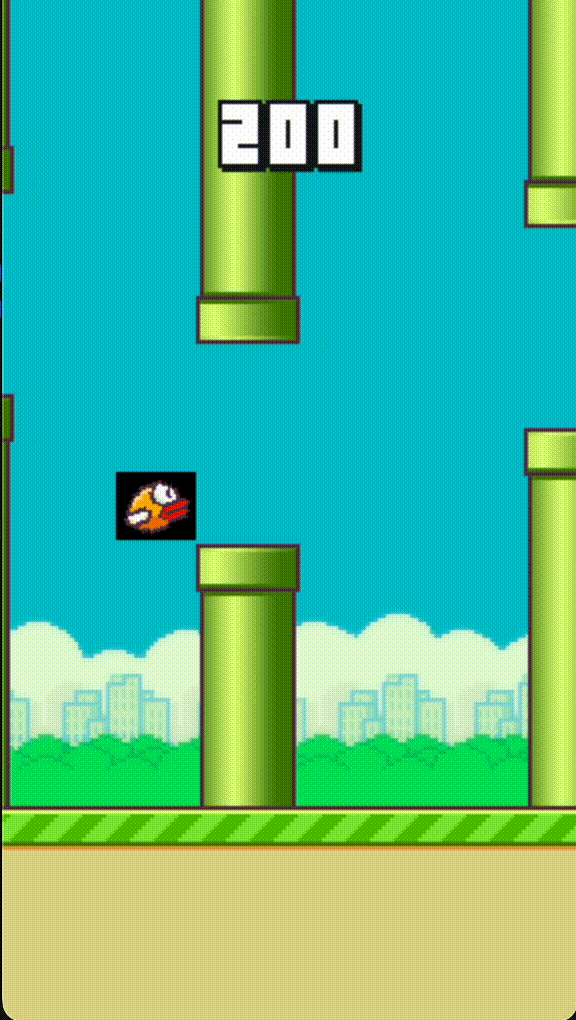
<style>
img[alt="flappy_bird.gif"] {
    width: 300px;
    display: block;
    margin: auto;
}
</style>

- **Goal:** train an agent that plays [Flappy Bird](https://en.wikipedia.org/wiki/Flappy_Bird) and collects as many score points as possible by flying through the pipes.
- **Episode end:** the episode terminates when the bird collides with a pipe or the ground.
- **Observation:** 12 values (`FlappyBirdEnv`, gymnasium API):
  - last pipe: horizontal position, top pipe's vertical position, bottom pipe's vertical position
  - next pipe: the same three values
  - next-next pipe: the same three values
  - bird: vertical position, vertical velocity, rotation
- **Action:** a float in $[0, 1]$; values below the threshold 0.5 have no effect (no flap).
- **Speed-up:** the pipes get faster every 30 score points and are twice as fast at a score of 120.
- **No reward:** the environment returns no reward. Designing a reward function that leads the agent towards high scores is part of the problem.

## Demonstration

- The code below lets a random agent (`env.action_space.sample()`) play one rendered episode.
- `reset()` returns the first observation; `step(action)` returns `(observation, reward, terminated, truncated, info)`.
- The reward is always `None`; `info["score"]` holds the number of pipes passed.

In [1]:
import os
import sys

# without a screen (headless server, CI, or HEADLESS=1), "human" rendering draws to pygame's
# invisible dummy display instead of opening a window
if os.environ.get("HEADLESS") == "1" or (
        sys.platform.startswith("linux") and not (os.environ.get("DISPLAY") or os.environ.get("WAYLAND_DISPLAY"))):
    os.environ["SDL_VIDEODRIVER"] = "dummy"

from flappy_bird_gymnasium.envs.flappy_bird_env import FlappyBirdEnv
import numpy as np

In [3]:
env = FlappyBirdEnv(render_mode="human")
obs, _ = env.reset()  # Here the env can be seeded
while True:
    # Next action:
    # (feed the observation to your agent here)
    action = env.action_space.sample()

    # Environment step:
    obs, reward, terminated, _, info = env.step(action)

    # The reward is returned but is allways None

    # Checking if the player is still alive
    if terminated:
        break

env.close()

In [4]:
print(f"The final score is {info['score']}!")

The final score is 0!


# Solution overview

- **Part 1, reward:** survival bonus, pipe reward, crash and ceiling penalties, plus potential-based shaping towards the gap centre.
- **Part 2, actions:** the float action has exactly 9 distinct effects, so the agent chooses among 9 discrete flap levels.
- **Part 2, observations:** 8 bird-centric features, including the pipe speed level, computed by a wrapper.
- **Part 2, algorithm:** PPO (stable-baselines3) with 8 parallel environments, 6 M training steps.
- **Learning curve:** training and evaluation curves, compared with the alternative designs we tried.
- **Evaluation:** 100 unseen episodes per policy against 5 other policies, with statistics and failure analysis.
- **Save / load:** policy saved as `agent/flappy_ppo.zip`, then reloaded and re-evaluated.
- **Re-running:** `TRAIN = False` (default) uses the saved agent and logs; `TRAIN = True` retrains ($\approx$ 30 min).
- **Requirement:** NumPy 2.3.5 (see `requirements.txt`); the environment's `int()` call on the action fails with NumPy 2.4 and newer.

## Setup

In [5]:
import os
# one math thread per process: the networks are tiny, and each parallel environment process
# would otherwise reserve large thread buffers
os.environ["OMP_NUM_THREADS"] = "1"
os.environ["OPENBLAS_NUM_THREADS"] = "1"
os.environ["MKL_NUM_THREADS"] = "1"

import glob
import shutil
import time
import warnings
import functools

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats
import gymnasium
import torch
import stable_baselines3
from stable_baselines3 import PPO
from stable_baselines3.common.env_util import make_vec_env
from stable_baselines3.common.vec_env import SubprocVecEnv, DummyVecEnv
from stable_baselines3.common.callbacks import EvalCallback

warnings.filterwarnings("ignore", message="Training and eval env are not of the same type")

TRAIN = False       # True -> train from scratch (~30 min). The training cell output below was produced
                    #         with TRAIN = True; False loads the saved agent and logs
SEED = 42

AGENT_DIR = "agent"
MODEL_PATH = os.path.join(AGENT_DIR, "flappy_ppo")     # -> agent/flappy_ppo.zip
LOG_DIR = "training_logs"
EXP_DIR = "experiments"                                 # logs of the alternative designs we compared
os.makedirs(AGENT_DIR, exist_ok=True)
FIG_DIR = os.path.join("docs", "images")                # figures shown in the README
VIDEO_PATH = os.path.join("docs", "evaluation_video.mp4")
os.makedirs(LOG_DIR, exist_ok=True)
os.makedirs(FIG_DIR, exist_ok=True)

print(f"numpy {np.__version__} | gymnasium {gymnasium.__version__} | "
      f"stable-baselines3 {stable_baselines3.__version__} | torch {torch.__version__} | CPU cores {os.cpu_count()}")

numpy 2.3.5 | gymnasium 1.3.0 | stable-baselines3 2.9.0 | torch 2.14.0+cpu | CPU cores 24


## Part 1: Design the Reward Function
Design a reward function that encourages the agent to:

- Stay alive for as long as possible.
- Successfully fly through pipes.
- Avoid collisions with pipes, the ground, and the ceiling.

Explain the reasoning behind your reward design and discuss any trade-offs.

### Our reward function

The environment returns no reward, so the reward below is computed entirely from the observation, the score in `info` and the termination flag.

| Component | Value | Purpose |
|---|---|---|
| Staying alive | $+0.1$ per step | Dense signal: every frame survived is good |
| Passing a pipe | $+1.0$ per pipe | The real objective; worth 10 frames of survival |
| Crash (pipe or ground) | $-1.0$, episode ends | Punishes collisions; dying also loses all future survival reward |
| Above the ceiling | $-0.5$ per step | The bird can leave the top of the screen (flaps are strong here); this keeps it in the playable area |
| Gap shaping | $F_{k+1} = \gamma\,\Phi(\boldsymbol{x}_{k+1}) - \Phi(\boldsymbol{x}_k)$ | Pulls the bird towards the centre of the next gap |

with the potential $\Phi(\boldsymbol{x}) = -\,|y_\text{bird} - y_\text{gap centre}|$ and $\Phi(\boldsymbol{x}_\text{terminal}) = 0$.

**Reasoning**

* **Survival and pipe rewards are aligned:** you cannot survive without passing pipes, so the dense $+0.1$ never conflicts with the goal. It provides a learning signal long before the first pipe is passed; with only $+1$ per pipe, a random agent almost never sees a reward.
* **Implicit crash cost:** with $\gamma = 0.99$, crashing costs $-1$ plus the lost future survival reward of up to $0.1/(1-\gamma) = 10$.
* **Potential-based shaping** (Ng, Harada & Russell, 1999): the discounted sum of the shaping terms telescopes to $-\Phi(\boldsymbol{x}_0)$, a constant for every policy, so **the optimal policy is unchanged**; only learning gets faster.

**Trade-offs**

* *Dense vs. sparse:* dense rewards learn faster but risk reward hacking. Here the proxy (survival) is aligned with the goal.
* *Size of the crash penalty:* very large penalties make the value function harder to fit and the agent overly cautious; all terms are of order 1, which suits PPO's value network.
* *Shaping strength:* stronger shaping guides more but adds reward noise; being potential-based, it affects speed, not the optimum.
* *Terminal potential:* $\Phi(\boldsymbol{x}_\text{terminal}) = 0$ (required for policy invariance) adds a small positive term $\le 0.5$ at death, always smaller than the $-1$ crash penalty.

In [6]:
GAMMA = 0.99

# screen geometry (288 x 512 px) in the normalised units of the observation
SCREEN_W, SCREEN_H = 288, 512
PLAYER_X = int(SCREEN_W * 0.2) / SCREEN_W           # fixed horizontal position of the bird
PIPE_W = 52 / SCREEN_W                              # pipe width
BIRD_H = 24 / SCREEN_H                              # bird height
GROUND_Y = (SCREEN_H * 0.79 - 1 - 24) / SCREEN_H    # bird y at which it touches the ground

R_ALIVE, R_PIPE, R_CRASH, R_CEILING = 0.1, 1.0, -1.0, -0.5
SHAPING_SCALE = 1.0


def target_gap(obs):
    # (top, bottom) of the gap the bird has to pass next: the 'last' pipe while the bird is
    # still inside it, otherwise the 'next' pipe
    if obs[0] + PIPE_W > PLAYER_X:
        return obs[1], obs[2]
    return obs[4], obs[5]


def gap_potential(obs):
    # Phi(s) = -|bird centre - gap centre|
    top, bottom = target_gap(obs)
    return -abs(float(obs[9] + BIRD_H / 2 - (top + bottom) / 2))


def reward_function(obs, score, prev_score, terminated, prev_potential):
    # Reward for one step of the Flappy Bird environment.
    #   obs             raw 12-dim observation after the step
    #   score, prev_score   pipes passed after / before the step (from info["score"])
    #   terminated      True if the bird hit a pipe or the ground
    #   prev_potential  Phi of the previous state
    # Returns (reward, Phi of the new state).
    reward = R_CRASH if terminated else R_ALIVE
    reward += R_PIPE * (score - prev_score)
    if obs[9] < 0:                                   # above the top of the screen
        reward += R_CEILING
    potential = 0.0 if terminated else gap_potential(obs)
    reward += SHAPING_SCALE * (GAMMA * potential - prev_potential)
    return reward, potential


class FlappyRewardWrapper(gymnasium.Wrapper):
    # adds our reward to the environment (which itself returns None)

    def reset(self, **kwargs):
        obs, info = self.env.reset(**kwargs)
        self.prev_score = 0
        self.prev_potential = gap_potential(obs)
        return obs, info

    def step(self, action):
        obs, _, terminated, truncated, info = self.env.step(action)
        score = int(info["score"])
        reward, self.prev_potential = reward_function(obs, score, self.prev_score, terminated,
                                                      self.prev_potential)
        self.prev_score = score
        info["raw_obs"] = obs                         # kept for the crash analysis
        return obs, reward, terminated, truncated, info

## Part 2: Choose and implement a RL algorithm that is suitable for the given environment.


### Step 1: action design

In `flappy_bird_env.py` the bird flaps only if `action > 0.5`, and then sets its velocity to `int(-13 * action)`. Because of the `int()` truncation, the continuous action has exactly **9 distinct effects**: no flap, or a flap with velocity $-6, -7, \dots, -13$. A discrete policy over these 9 levels therefore loses nothing compared with continuous control.

| Design (same PPO settings) | Actions | Best evaluation return (3 M steps) |
|---|---|---|
| Flap / no-flap, full flap | no flap, $-13$ (action 1.0) | 10 |
| Flap / no-flap, original-game flap | no flap, $-9$ | 304 |
| Flap / no-flap, gentle flap | no flap, $-7$ | 492 |
| Continuous PPO (Gaussian policy) | $u \in [0,1]$ | 407 |
| 4 actions | no flap, $-7$, $-10$, $-13$ | 500 |
| **9 actions (final)** | no flap, $-6, \dots, -13$ | **869** (877 after 6 M steps) |

A fixed flap works only if it is gentle; being able to choose the strength is much better, especially when the pipes are fast and the bird has few frames to change height.

### Step 2: observation design

The 12 raw observations contain **no information about the pipe speed**, which changes every 30 points, so the state is not Markov. With the raw features, the network must also learn *which* of the three pipe slots is next and subtract heights by itself. A wrapper therefore feeds the agent **8 bird-centric features**, computed only from the observation and `info["score"]`:

| Feature | Meaning |
|---|---|
| $d_1$ | horizontal distance until the bird has passed the next pipe |
| $y_\text{bird} - y^\text{top}_1$ | clearance to the gap's upper edge (negative $\rightarrow$ collision) |
| $y^\text{bot}_1 - (y_\text{bird} + h)$ | clearance to the gap's lower edge (negative $\rightarrow$ collision) |
| $d_2$, ... | the same three values for the pipe after that |
| $v_y$ | vertical velocity |
| speed level | $\min(\lfloor\text{score}/30\rfloor, 4)/4$: pipe speed (restores the Markov property) |

In [7]:
# one representative action value per distinct effect: no flap, then vel_y = -6, -7, ..., -13
FLAP_LEVELS = [0.0, 0.52, 0.55, 0.62, 0.70, 0.77, 0.85, 0.93, 1.0]
print("flap velocity per action:", [int(-13 * a) if a > 0.5 else "no flap" for a in FLAP_LEVELS])


def speed_level(score):
    # the environment adds 1 px/frame to the pipe speed every 30 points, at most +4
    return min(score // 30, 4)


class DiscreteFlapAction(gymnasium.ActionWrapper):
    # action index -> float action for the environment (passed as a plain Python float)
    def __init__(self, env, levels=FLAP_LEVELS):
        super().__init__(env)
        self.levels = list(levels)
        self.action_space = gymnasium.spaces.Discrete(len(self.levels))

    def action(self, act):
        return float(self.levels[int(act)])


class BirdCentricObservation(gymnasium.Wrapper):
    # 12 raw features (+ score) -> 8 bird-centric features (see table above)
    def __init__(self, env):
        super().__init__(env)
        self.observation_space = gymnasium.spaces.Box(-np.inf, np.inf, shape=(8,), dtype=np.float32)

    def _features(self, o):
        pipes = [(o[0], o[1], o[2]), (o[3], o[4], o[5]), (o[6], o[7], o[8])]
        ahead = [p for p in pipes if p[0] + PIPE_W > PLAYER_X][:2]    # next two pipes not yet passed
        f = []
        for x, top, bottom in ahead:
            f += [x + PIPE_W - PLAYER_X, o[9] - top, bottom - (o[9] + BIRD_H)]
        return np.array(f + [o[10], speed_level(self.score) / 4], dtype=np.float32)

    def reset(self, **kwargs):
        obs, info = self.env.reset(**kwargs)
        self.score = 0
        return self._features(obs), info

    def step(self, action):
        obs, reward, terminated, truncated, info = self.env.step(action)
        self.score = int(info["score"])
        return self._features(obs), reward, terminated, truncated, info


class RawObservation(gymnasium.ObservationWrapper):
    # the original 12 features (used only for the comparison run and the hand-written baseline)
    def __init__(self, env):
        super().__init__(env)
        self.observation_space = gymnasium.spaces.Box(-np.inf, np.inf, shape=(12,), dtype=np.float32)

    def observation(self, obs):
        return obs.astype(np.float32)


def make_env(features="bird", levels=FLAP_LEVELS, render_mode=None, score_limit=None, max_steps=None):
    # Flappy Bird environment + our reward + observation features + discrete flap levels
    # (levels: the 9 flap levels by default; the binary comparison agents use 2 levels)
    from flappy_bird_gymnasium.envs.flappy_bird_env import FlappyBirdEnv   # also inside worker processes
    env = FlappyBirdEnv(render_mode=render_mode, score_limit=score_limit)
    if max_steps is not None:
        env = gymnasium.wrappers.TimeLimit(env, max_episode_steps=max_steps)
    env = FlappyRewardWrapper(env)
    env = BirdCentricObservation(env) if features == "bird" else RawObservation(env)
    return DiscreteFlapAction(env, levels)


env = make_env()
obs, _ = env.reset(seed=SEED)
print("agent observation space:", env.observation_space, "| action space:", env.action_space)
print("first observation:", np.round(obs, 3))
env.close()

flap velocity per action: ['no flap', -6, -7, -8, -9, -10, -11, -12, -13]
agent observation space: Box(-inf, inf, (8,), float32) | action space: Discrete(9)
first observation: [ 0.983  0.281 -0.133  0.983  0.477  0.477 -0.9    0.   ]


**Sanity check of the reward:** a random agent and an agent that never flaps both crash quickly with a low return.

In [8]:
env = make_env()
rng = np.random.default_rng(SEED)
for name, choose in [("random", lambda o: int(rng.integers(len(FLAP_LEVELS)))), ("never flap", lambda o: 0)]:
    obs, _ = env.reset(seed=SEED)
    ret, steps, done = 0.0, 0, False
    while not done:
        obs, r, terminated, truncated, info = env.step(choose(obs))
        ret, steps, done = ret + r, steps + 1, terminated or truncated
    print(f"{name:>10}: return = {ret:6.2f}, steps = {steps:3d}, pipes = {info['score']}")
env.close()

    random: return =  -8.27, steps =  50, pipes = 0
never flap: return =   2.28, steps =  31, pipes = 0


### Step 3: algorithm choice: Proximal Policy Optimization (PPO)

| Algorithm | Fits this task? |
|---|---|
| REINFORCE (Monte Carlo policy gradient) | Works in principle, but very high variance; episodes become thousands of steps long |
| DQN | Fits discrete actions and is sample-efficient, but max-based targets overestimate values and function approximation + bootstrapping + off-policy data (the *deadly triad*) can make it unstable; sensitive to tuning |
| DDPG / TD3 / SAC | Designed for continuous actions. The native action *is* continuous, but only 9 distinct effects exist, and a threshold at 0.5 makes $q(\boldsymbol{x},\boldsymbol{u})$ a step function of the action: its gradient $\nabla_{\boldsymbol{u}} \hat q$, which all three use to update the actor, is zero or misleading. PPO's $\nabla_{\boldsymbol{\theta}} \ln \pi(\boldsymbol{u}|\boldsymbol{x},\boldsymbol{\theta})\,\hat a$ does not need it |
| **PPO** | Works with discrete and continuous actions, stable, little tuning; clipped updates protect against destructive policy changes |

PPO is an on-policy actor-critic method: an actor $\pi(\boldsymbol{u}|\boldsymbol{x},\boldsymbol{\theta})$ (here a softmax over the 9 flap levels) and a critic $\hat v(\boldsymbol{x},\boldsymbol{w})$. Notation as in the lecture: time step $k$, state $\boldsymbol{x}_k$, action $\boldsymbol{u}_k$, reward $r_{k+1}$, PPO iteration $j$.

$$L^{\text{CLIP}}(\boldsymbol{\theta}) = \mathbb{E}_{\pi_{\boldsymbol{\theta}_j}}\Big[\min\big(\rho_k(\boldsymbol{\theta})\,\hat a_k,\ \operatorname{clip}(\rho_k(\boldsymbol{\theta}), 1-\epsilon, 1+\epsilon)\,\hat a_k\big)\Big], \qquad \rho_k(\boldsymbol{\theta}) = \frac{\pi(\boldsymbol{u}_k|\boldsymbol{x}_k,\boldsymbol{\theta})}{\pi(\boldsymbol{u}_k|\boldsymbol{x}_k,\boldsymbol{\theta}_j)}$$

$$\hat a_k = \sum_{i\ge0} (\gamma\lambda)^i \delta_{k+i}, \quad \delta_k = r_{k+1} + \gamma\,\hat v(\boldsymbol{x}_{k+1},\boldsymbol{w}) - \hat v(\boldsymbol{x}_k,\boldsymbol{w}), \qquad L = -L^{\text{CLIP}} + c_1 \big(\hat v(\boldsymbol{x}_k,\boldsymbol{w}) - \hat g_k\big)^2 - c_2\,\mathcal{H}[\pi(\cdot|\boldsymbol{x}_k,\boldsymbol{\theta})]$$

Clipping the probability ratio removes the incentive to move the policy far from the old one in a single update (a cheap first-order version of TRPO's trust region), so each batch can safely be reused for several epochs. $\rho_k$ is the importance sampling ratio between the new and the old policy, $\hat g_k = \hat a_k + \hat v(\boldsymbol{x}_k,\boldsymbol{w})$ the return target of the critic; the entropy bonus $c_2\mathcal{H}$ keeps the policy exploring.

```
for iteration = 1, 2, ...
    run pi_old in 8 parallel environments for 2048 steps each   -> 16 384 transitions
    compute advantages A_hat with GAE(gamma, lambda) and returns R_hat = A_hat + V(s)
    for 10 epochs, for minibatches of 512: gradient step on L (Adam)
```

### Hyperparameters

| Hyperparameter | Value | Reasoning |
|---|---|---|
| Parallel environments | 8 | more diverse data per update, faster training |
| Steps per env per update | 2048 | 16 384 transitions per update |
| Minibatch size, epochs | 512, 10 | PPO defaults scaled to the batch |
| $\gamma$, GAE $\lambda$ | 0.99, 0.95 | horizon $\approx 1/(1-\gamma) = 100$ frames $\approx$ 3--5 pipes ahead |
| Learning rate | $3\cdot10^{-4} \rightarrow 0$ (linear) | large steps early, small steps late for a stable final policy |
| Clip $\epsilon$ | 0.2 | PPO default |
| Entropy coefficient $c_2$ | 0.01 | keeps exploring early, still converges |
| Value coefficient $c_1$, gradient clipping | 0.5, 0.5 | defaults |
| Networks | actor and critic, $2 \times 128$, tanh | small input (8 features) |
| Total steps | 6,000,000 | the high-speed phase (score $\ge$ 120) is only reached late in training, so it needs many steps |

An `EvalCallback` evaluates the deterministic policy on 10 separate episodes (capped at 300 pipes) every 100 000 steps and keeps the best model.

In [9]:
N_ENVS = 8
TOTAL_TIMESTEPS = 6000000
EVAL_FREQ = 100_000
EVAL_SCORE_CAP_TRAIN = 300


def linear_schedule(initial_value):
    def schedule(progress_remaining):          # goes from 1 (start) to 0 (end of training)
        return progress_remaining * initial_value
    return schedule


HYPERPARAMS = dict(n_steps=2048, batch_size=512, n_epochs=10, gamma=GAMMA, gae_lambda=0.95,
                   learning_rate=linear_schedule(3e-4), clip_range=0.2, ent_coef=0.01, vf_coef=0.5,
                   max_grad_norm=0.5, policy_kwargs=dict(net_arch=dict(pi=[128, 128], vf=[128, 128])))

if TRAIN:
    for f in glob.glob(os.path.join(LOG_DIR, "*")):
        os.remove(f)
    # 8 training environments in parallel processes; Monitor logs one CSV row per episode
    train_env = make_vec_env(make_env, n_envs=N_ENVS, seed=SEED, vec_env_cls=SubprocVecEnv,
                             monitor_dir=LOG_DIR, monitor_kwargs={"info_keywords": ("score",)})
    eval_env = make_vec_env(make_env, n_envs=5, seed=SEED + 1000,
                            env_kwargs={"score_limit": EVAL_SCORE_CAP_TRAIN})
    eval_callback = EvalCallback(eval_env, n_eval_episodes=10, eval_freq=EVAL_FREQ // N_ENVS,
                                 deterministic=True, best_model_save_path=LOG_DIR, log_path=LOG_DIR, verbose=0)

    model = PPO("MlpPolicy", train_env, seed=SEED, verbose=0, **HYPERPARAMS)
    print(model.policy)
    start = time.time()
    model.learn(total_timesteps=TOTAL_TIMESTEPS, callback=eval_callback)
    print(f"Training took {(time.time() - start) / 60:.1f} min")
    model.save(os.path.join(LOG_DIR, "final_model"))
    train_env.close()
    eval_env.close()
else:
    print("TRAIN = False: using the saved agent and training logs.")

ActorCriticPolicy(
  (features_extractor): FlattenExtractor(
    (flatten): Flatten(start_dim=1, end_dim=-1)
  )
  (pi_features_extractor): FlattenExtractor(
    (flatten): Flatten(start_dim=1, end_dim=-1)
  )
  (vf_features_extractor): FlattenExtractor(
    (flatten): Flatten(start_dim=1, end_dim=-1)
  )
  (mlp_extractor): MlpExtractor(
    (policy_net): Sequential(
      (0): Linear(in_features=8, out_features=128, bias=True)
      (1): Tanh()
      (2): Linear(in_features=128, out_features=128, bias=True)
      (3): Tanh()
    )
    (value_net): Sequential(
      (0): Linear(in_features=8, out_features=128, bias=True)
      (1): Tanh()
      (2): Linear(in_features=128, out_features=128, bias=True)
      (3): Tanh()
    )
  )
  (action_net): Linear(in_features=128, out_features=9, bias=True)
  (value_net): Linear(in_features=128, out_features=1, bias=True)
)


Training took 30.6 min


Plot the learning curve of the training process. Clearly label axes (e.g., episode vs. total reward) and make it readable.

1. **Total reward per training episode** (symmetric log scale, 100-episode moving average).
2. **Pipes passed per training episode** (log scale), with the speed-up thresholds at 30 / 60 / 90 / 120 pipes.
3. **Deterministic evaluation during training** (10 episodes, capped at 300 pipes) for the final design and the alternatives we compared.

Training episodes use the *stochastic* policy, so they are noisier than evaluation episodes. The monitor only logs **finished** episodes.

8438 finished training episodes, 5,987,040 steps in finished episodes


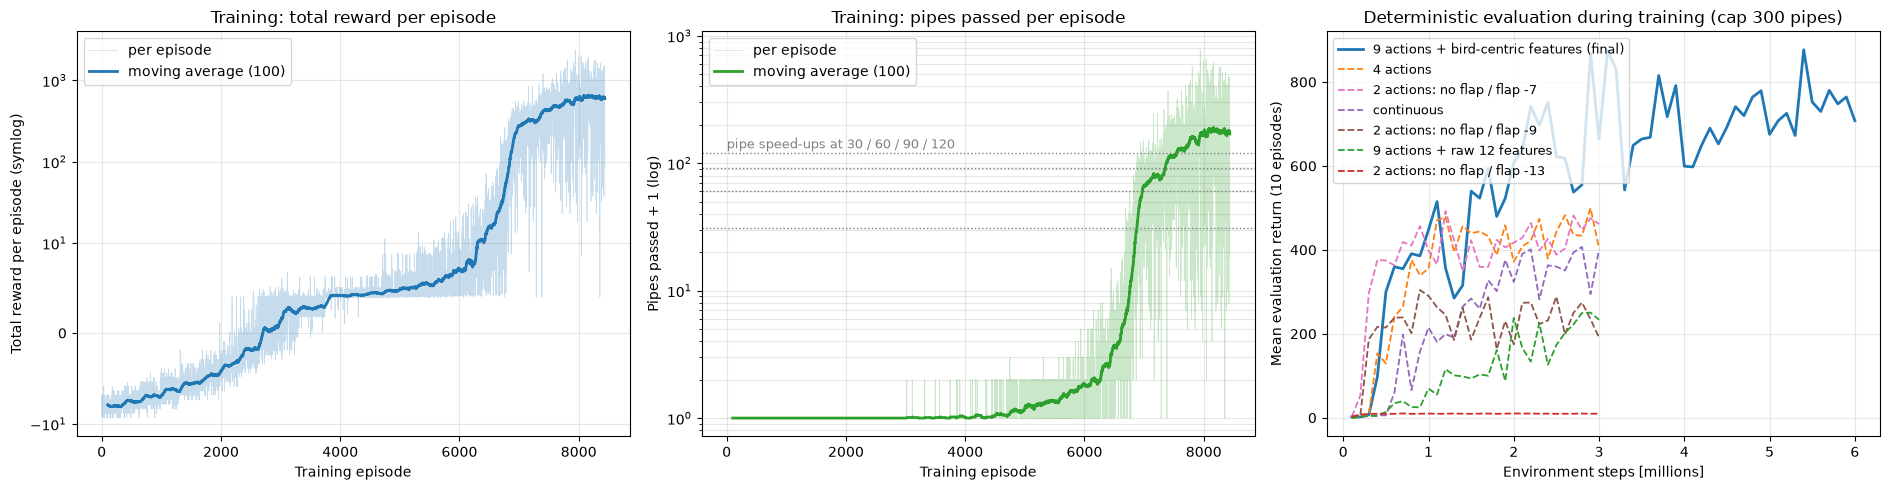

In [9]:
def load_monitor_logs(log_dir):
    frames = [pd.read_csv(f, skiprows=1) for f in glob.glob(os.path.join(log_dir, "*.monitor.csv"))]
    df = pd.concat(frames).sort_values("t").reset_index(drop=True)
    df["episode"] = np.arange(1, len(df) + 1)
    return df

logs = load_monitor_logs(LOG_DIR)
evals = np.load(os.path.join(LOG_DIR, "evaluations.npz"))
WINDOW = 100
print(f"{len(logs)} finished training episodes, {logs['l'].sum():,} steps in finished episodes")

fig, axes = plt.subplots(1, 3, figsize=(19, 5))

ax = axes[0]
ax.plot(logs["episode"], logs["r"], color="tab:blue", alpha=0.25, lw=0.5, label="per episode")
ax.plot(logs["episode"], logs["r"].rolling(WINDOW).mean(), color="tab:blue", lw=2, label=f"moving average ({WINDOW})")
ax.set_yscale("symlog", linthresh=10)
ax.set_xlabel("Training episode")
ax.set_ylabel("Total reward per episode (symlog)")
ax.set_title("Training: total reward per episode")
ax.legend()
ax.grid(alpha=0.3)

ax = axes[1]
ax.plot(logs["episode"], logs["score"] + 1, color="tab:green", alpha=0.25, lw=0.5, label="per episode")
ax.plot(logs["episode"], logs["score"].rolling(WINDOW).mean() + 1, color="tab:green", lw=2, label=f"moving average ({WINDOW})")
for s in (30, 60, 90, 120):
    ax.axhline(s + 1, color="grey", ls=":", lw=1)
ax.text(1, 121 * 1.08, "pipe speed-ups at 30 / 60 / 90 / 120", color="grey", fontsize=9)
ax.set_yscale("log")
ax.set_xlabel("Training episode")
ax.set_ylabel("Pipes passed + 1 (log)")
ax.set_title("Training: pipes passed per episode")
ax.legend(loc="upper left")
ax.grid(alpha=0.3, which="both")

ax = axes[2]
curves = [("9 actions + bird-centric features (final)", evals, "tab:blue", "-")]
for name, label, color in [("discrete4", "4 actions", "tab:orange"),
                           ("binary_flap7", "2 actions: no flap / flap -7", "tab:pink"),
                           ("continuous", "continuous", "tab:purple"),
                           ("binary_flap9", "2 actions: no flap / flap -9", "tab:brown"),
                           ("raw_features", "9 actions + raw 12 features", "tab:green"),
                           ("discrete2", "2 actions: no flap / flap -13", "tab:red")]:
    f = os.path.join(EXP_DIR, name, "evaluations.npz")
    if os.path.exists(f):
        curves.append((label, np.load(f), color, "--"))
for label, d, color, ls in curves:
    ax.plot(d["timesteps"] / 1e6, d["results"].mean(axis=1), ls, color=color, lw=2 if ls == "-" else 1.3, label=label)
ax.set_xlabel("Environment steps [millions]")
ax.set_ylabel("Mean evaluation return (10 episodes)")
ax.set_title("Deterministic evaluation during training (cap 300 pipes)")
ax.legend(fontsize=9)
ax.grid(alpha=0.3)

plt.tight_layout()
plt.savefig(os.path.join(FIG_DIR, "learning_curve.png"), dpi=150)
plt.show()

## Evaluation
Test the learned policy considering a statistical significant number of episodes and report on the performance using representative metrics.

**Protocol:** every policy plays **100 new episodes** with the same unseen seeds, using deterministic actions. Episodes are capped at **1000 pipes**; a capped episode counts as a success.

**Policies compared**
* **Random:** uniform over the 9 flap levels
* **Hand-written rule:** flap with velocity $-8$ whenever the bird's bottom is less than 15 px above the bottom of the next gap
* **PPO, raw 12 features:** same algorithm and actions, but without our observation features
* **PPO, binary flap $-9$ / $-7$:** same algorithm and features, but only *no flap / flap* with a fixed strength (the classic game)
* **PPO, final:** our agent

**Metrics:** pipes per episode (mean ± SD, 95 % confidence interval, median and interquartile range), survival time, success rates, **the speed level at which episodes end** and how they end (ground, upper or lower pipe). A one-sided **Mann–Whitney U test** checks whether the final agent is significantly better; it is non-parametric because the scores are skewed and capped.

In [10]:
N_EVAL_EPISODES = 100
EVAL_SCORE_CAP = 1000
EVAL_SEED = 12_345           # seeds never used in training


def crash_cause(raw_obs, truncated):
    if truncated:
        return "reached cap"
    if raw_obs[9] >= GROUND_Y - 0.01:
        return "ground"
    top, bottom = target_gap(raw_obs)
    return "upper pipe" if raw_obs[9] + BIRD_H / 2 < (top + bottom) / 2 else "lower pipe"


class HandWrittenRule:
    # baseline controller on the raw observation: flap (vel -8) when close to the gap's bottom edge
    def predict(self, obs, deterministic=True):
        acts = []
        for o in np.atleast_2d(obs):
            _, bottom = target_gap(o)
            acts.append(3 if o[9] + BIRD_H > bottom - 0.03 else 0)
        return np.array(acts), None


def evaluate(policy, n_episodes, features="bird", levels=FLAP_LEVELS, n_envs=12, score_cap=EVAL_SCORE_CAP,
             seed=EVAL_SEED):
    # runs n_episodes episodes (policy=None -> uniformly random actions); one row per episode
    n_envs = min(n_envs, n_episodes)
    per_env = [n_episodes // n_envs + (i < n_episodes % n_envs) for i in range(n_envs)]
    env = make_vec_env(make_env, n_envs=n_envs, seed=seed, vec_env_cls=SubprocVecEnv,
                       env_kwargs={"features": features, "levels": levels, "score_limit": score_cap})
    rng = np.random.default_rng(seed)
    obs = env.reset()
    done_count, rows = [0] * n_envs, []
    while any(d < t for d, t in zip(done_count, per_env)):
        if policy is None:
            actions = rng.integers(len(FLAP_LEVELS), size=n_envs)
        else:
            actions, _ = policy.predict(obs, deterministic=True)
        obs, _, dones, infos = env.step(actions)
        for i in np.flatnonzero(dones):
            if done_count[i] < per_env[i]:
                info = infos[i]
                truncated = info.get("TimeLimit.truncated", False) or info["score"] >= score_cap
                rows.append(dict(pipes=info["score"], frames=info["episode"]["l"],
                                 speed_level=speed_level(info["score"]),
                                 cause=crash_cause(info["raw_obs"], truncated)))
            done_count[i] += 1
    env.close()
    df = pd.DataFrame(rows)
    df["seconds"] = df["frames"] / 30
    return df


def summarize(df, name):
    n = len(df)
    mean, sd = df["pipes"].mean(), df["pipes"].std(ddof=1)
    half = stats.t.ppf(0.975, n - 1) * sd / np.sqrt(n)
    return pd.Series({
        "episodes": n,
        "mean pipes": round(mean, 1),
        "SD": round(sd, 1),
        "95% CI of mean": f"[{mean - half:.1f}, {mean + half:.1f}]",
        "median [IQR]": f"{df['pipes'].median():.0f} [{df['pipes'].quantile(.25):.0f}-{df['pipes'].quantile(.75):.0f}]",
        "min / max": f"{df['pipes'].min()} / {df['pipes'].max()}",
        "mean survival [s]": round(df["seconds"].mean(), 1),
        ">= 30 pipes (1st speed-up) [%]": round(100 * (df["pipes"] >= 30).mean(), 1),
        ">= 120 pipes (max speed) [%]": round(100 * (df["pipes"] >= 120).mean(), 1),
        f"reached cap ({EVAL_SCORE_CAP}) [%]": round(100 * (df["cause"] == "reached cap").mean(), 1),
    }, name=name)

In [11]:
policy = PPO.load(os.path.join(LOG_DIR, "best_model")) if TRAIN else PPO.load(MODEL_PATH)

start = time.time()
results = {
    "Random": evaluate(None, N_EVAL_EPISODES),
    "Hand-written rule": evaluate(HandWrittenRule(), N_EVAL_EPISODES, features="raw"),
    "PPO, raw 12 features": evaluate(PPO.load(os.path.join(EXP_DIR, "raw_features", "best_model")),
                                     N_EVAL_EPISODES, features="raw"),
    "PPO, binary flap -9": evaluate(PPO.load(os.path.join(EXP_DIR, "binary_flap9", "best_model")),
                                    N_EVAL_EPISODES, levels=[0.0, 0.70]),
    "PPO, binary flap -7": evaluate(PPO.load(os.path.join(EXP_DIR, "binary_flap7", "best_model")),
                                    N_EVAL_EPISODES, levels=[0.0, 0.55]),
    "PPO, final": evaluate(policy, N_EVAL_EPISODES),
}
print(f"Evaluation took {(time.time() - start) / 60:.1f} min")
display(pd.concat([summarize(df, name) for name, df in results.items()], axis=1))

final = results["PPO, final"]["pipes"]
for name in [n for n in results if n != "PPO, final"]:
    u = stats.mannwhitneyu(final, results[name]["pipes"], alternative="greater")
    effect = 2 * u.statistic / (len(final) * len(results[name])) - 1
    print(f"Mann-Whitney U, final PPO > {name:<22}: p = {u.pvalue:.1e}, rank-biserial effect size r = {effect:.2f}")

Evaluation took 3.8 min


,Random,Hand-written rule,"PPO, raw 12 features","PPO, binary flap -9","PPO, binary flap -7","PPO, final"
episodes,100,100,100,100,100,100
mean pipes,0.0,60.5,44.6,49.4,102.5,253.8
SD,0.0,28.7,32.5,22.6,33.2,168.9
95% CI of mean,"[0.0, 0.0]","[54.8, 66.2]","[38.2, 51.1]","[44.9, 53.9]","[95.9, 109.1]","[220.3, 287.3]"
median [IQR],0 [0-0],65 [37-83],36 [17-63],45 [35-66],98 [77-121],188 [143-339]
min / max,0 / 0,2 / 115,2 / 139,4 / 104,29 / 200,91 / 857
mean survival [s],1.7,66.7,50.6,57.0,101.4,200.0
>= 30 pipes (1st speed-up) [%],0.0,78.0,60.0,91.0,99.0,100.0
>= 120 pipes (max speed) [%],0.0,0.0,2.0,0.0,27.0,85.0
reached cap (1000) [%],0.0,0.0,0.0,0.0,0.0,0.0


Mann-Whitney U, final PPO > Random                : p = 2.8e-39, rank-biserial effect size r = 1.00
Mann-Whitney U, final PPO > Hand-written rule     : p = 2.4e-33, rank-biserial effect size r = 0.98
Mann-Whitney U, final PPO > PPO, raw 12 features  : p = 3.4e-33, rank-biserial effect size r = 0.98
Mann-Whitney U, final PPO > PPO, binary flap -9   : p = 2.2e-34, rank-biserial effect size r = 1.00
Mann-Whitney U, final PPO > PPO, binary flap -7   : p = 1.1e-22, rank-biserial effect size r = 0.80


**Where and how do the episodes end?** The pipe speed increases at 30, 60, 90 and 120 pipes, so we look at the speed level at the end of each episode and at the type of collision.

Final PPO: episodes ending at each speed level (0 = slowest, 4 = fastest)


cause,lower pipe,upper pipe,All
speed_level,,,
3,0,15,15
4,15,70,85
All,15,85,100


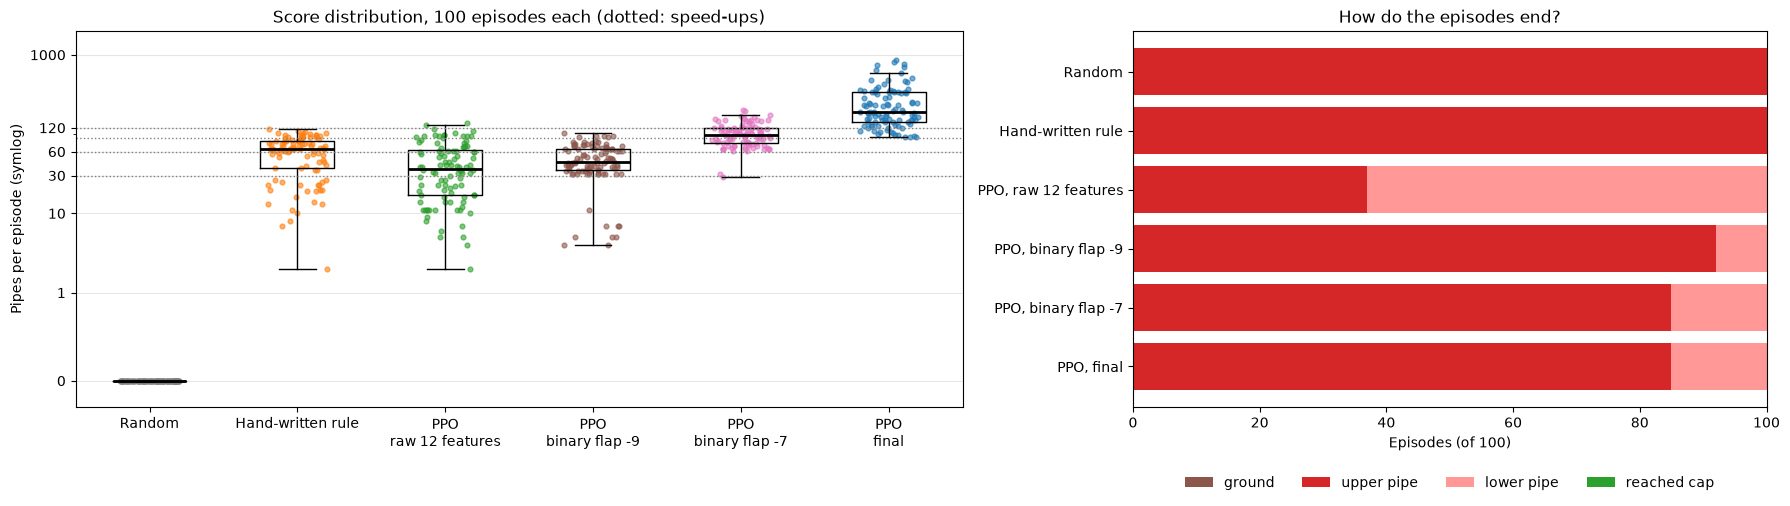

In [12]:
final_df = results["PPO, final"]
print("Final PPO: episodes ending at each speed level (0 = slowest, 4 = fastest)")
display(pd.crosstab(final_df["speed_level"], final_df["cause"], margins=True))

fig, axes = plt.subplots(1, 2, figsize=(18, 5.2), gridspec_kw={"width_ratios": [1.4, 1]})

ax = axes[0]
colors = {"Random": "tab:grey", "Hand-written rule": "tab:orange", "PPO, raw 12 features": "tab:green",
          "PPO, binary flap -9": "tab:brown", "PPO, binary flap -7": "tab:pink", "PPO, final": "tab:blue"}
rng = np.random.default_rng(0)
for i, (name, df) in enumerate(results.items()):
    y = df["pipes"].to_numpy()
    ax.boxplot(y, positions=[i], widths=0.5, showfliers=False, medianprops=dict(color="black", lw=2))
    ax.scatter(i + rng.uniform(-0.2, 0.2, len(y)), y, s=12, alpha=0.6, color=colors[name])
for s in (30, 60, 90, 120):
    ax.axhline(s, color="grey", ls=":", lw=1)
ax.set_yscale("symlog", linthresh=1)
ax.set_ylim(-0.3, 2000)
ax.set_yticks([0, 1, 10, 30, 60, 120, 1000])
ax.set_yticklabels(["0", "1", "10", "30", "60", "120", "1000"])
ax.set_xticks(range(len(results)))
ax.set_xticklabels([n.replace(", ", "\n") for n in results])
ax.set_ylabel("Pipes per episode (symlog)")
ax.set_title("Score distribution, 100 episodes each (dotted: speed-ups)")
ax.grid(alpha=0.3, axis="y")

ax = axes[1]
causes = ["ground", "upper pipe", "lower pipe", "reached cap"]
cause_colors = ["#8c564b", "#d62728", "#ff9896", "#2ca02c"]
left = np.zeros(len(results))
for c, col in zip(causes, cause_colors):
    vals = np.array([df["cause"].value_counts().get(c, 0) for df in results.values()])
    ax.barh(range(len(results)), vals, left=left, color=col, label=c)
    left += vals
ax.set_yticks(range(len(results)))
ax.set_yticklabels(list(results))
ax.invert_yaxis()
ax.set_xlabel("Episodes (of 100)")
ax.set_title("How do the episodes end?")
ax.legend(ncol=4, loc="upper center", bbox_to_anchor=(0.5, -0.15), frameon=False)

plt.tight_layout()
plt.savefig(os.path.join(FIG_DIR, "evaluation.png"), dpi=150)
plt.show()

## Save the learned policy to hard disk.

In [13]:
policy.save(MODEL_PATH)
print(f"Saved policy to {MODEL_PATH}.zip ({os.path.getsize(MODEL_PATH + '.zip') / 1024:.0f} kB)")

Saved policy to agent\flappy_ppo.zip (464 kB)


## Load the saved policy
Make sure that the policy can be loaded and evaluated 
successfully.

In [14]:
loaded_policy = PPO.load(MODEL_PATH)

# 1) the loaded policy chooses exactly the same actions as the one in memory
env = make_env(score_limit=50)
obs, _ = env.reset(seed=999)
observations = []
for _ in range(1000):
    observations.append(obs)
    obs, _, terminated, truncated, _ = env.step(loaded_policy.predict(obs, deterministic=True)[0])
    if terminated or truncated:
        obs, _ = env.reset()
env.close()
observations = np.array(observations)
same = np.array_equal(policy.predict(observations, deterministic=True)[0],
                      loaded_policy.predict(observations, deterministic=True)[0])
print("Loaded policy chooses identical actions:", same)
assert same

# 2) the loaded policy can be evaluated on new episodes
loaded_results = evaluate(loaded_policy, n_episodes=20, seed=777)
display(summarize(loaded_results, "loaded policy, 20 new episodes").to_frame())

Loaded policy chooses identical actions: True


,"loaded policy, 20 new episodes"
episodes,20
mean pipes,278.2
SD,161.1
95% CI of mean,"[202.8, 353.5]"
median [IQR],226 [144-376]
min / max,91 / 629
mean survival [s],215.5
>= 30 pipes (1st speed-up) [%],100.0
>= 120 pipes (max speed) [%],90.0
reached cap (1000) [%],0.0


## Evaluation video (optional)

One episode of the loaded agent, limited to 60 seconds, saved as `evaluation_video.mp4`.

In [15]:
import base64
import subprocess
import tempfile

import imageio_ffmpeg
from gymnasium.wrappers import RecordVideo
from IPython.display import HTML

VIDEO_DIR = "video_tmp"
shutil.rmtree(VIDEO_DIR, ignore_errors=True)
video_env = RecordVideo(make_env(render_mode="rgb_array", max_steps=1800), VIDEO_DIR,
                        episode_trigger=lambda ep: True, name_prefix="flappy")
obs, _ = video_env.reset(seed=2024)
done = False
while not done:
    obs, _, terminated, truncated, info = video_env.step(loaded_policy.predict(obs, deterministic=True)[0])
    done = terminated or truncated
video_env.close()
print(f"Recorded episode: {info['score']} pipes, crashed = {terminated}")
shutil.move(glob.glob(os.path.join(VIDEO_DIR, "*.mp4"))[0], VIDEO_PATH)
shutil.rmtree(VIDEO_DIR, ignore_errors=True)

# embed the video in the notebook: a WebM copy for viewers without H.264 (e.g. VS Code), the MP4 for browsers
webm_path = os.path.join(tempfile.gettempdir(), "evaluation_video.webm")
subprocess.run([imageio_ffmpeg.get_ffmpeg_exe(), "-y", "-loglevel", "error", "-i", VIDEO_PATH,
                "-c:v", "libvpx-vp9", "-b:v", "200k", webm_path], check=True)


def data_uri(path, mime):
    with open(path, "rb") as f:
        return f"data:{mime};base64," + base64.b64encode(f.read()).decode()


HTML(f'<video width="300" controls><source src="{data_uri(webm_path, "video/webm")}" type="video/webm">'
     f'<source src="{data_uri(VIDEO_PATH, "video/mp4")}" type="video/mp4"></video>')

Recorded episode: 51 pipes, crashed = False


## Discussion

**Results** (100 unseen episodes per policy):

| Policy | Mean $\pm$ SD pipes | Median [IQR] | Min / max | $\geq$ 120 pipes (max speed) |
|---|---|---|---|---|
| Random | $0.0 \pm 0.0$ | 0 [0--0] | 0 / 0 | 0 % |
| PPO, raw 12 features | $44.6 \pm 32.5$ | 36 [17--63] | 2 / 139 | 2 % |
| PPO, flap / no-flap $-9$ | $49.4 \pm 22.6$ | 45 [35--66] | 4 / 104 | 0 % |
| Hand-written rule | $60.5 \pm 28.7$ | 65 [37--83] | 2 / 115 | 0 % |
| PPO, flap / no-flap $-7$ | $102.5 \pm 33.2$ | 98 [77--121] | 29 / 200 | 27 % |
| **PPO, final** | $\mathbf{253.8 \pm 168.9}$ | **188 [143--339]** | **91 / 857** | **85 %** |

* The final agent is significantly better than every other policy (Mann--Whitney U, $p \leq 1.1 \cdot 10^{-22}$; effect size $r = 0.80$ against the best flap / no-flap agent, $r \geq 0.98$ against all others). 95 % confidence interval of its mean: [220, 287] pipes.
* It **never crashed before 90 pipes**; 85 % of the episodes reach the maximum pipe speed, the best one 857 pipes ($\approx$ 9 min of game time). Scores are right-skewed (median < mean), so the median is the robust summary.
* **Failure mode:** all crashes happen at the two fastest speed levels, 85 % against the upper pipe. At 8 px/frame only $\approx$ 18 frames separate two pipes, which leaves little time to change height when consecutive gaps differ a lot.

**Learning curve:** the bird first learns to survive longer (episodes 0--6800); between episodes 6800 and 7000 (0.45--0.8 M steps) it learns to pass gaps reliably (from about 13 to 65 pipes per episode). The evaluation return reaches $\approx$ 870 (close to the 300-pipe evaluation cap) after $\approx$ 3 M steps and then fluctuates between 600 and 877, because performance at maximum speed is variable and only 10 evaluation episodes are used; hence the best checkpoint is kept.

**What mattered most:** understanding the environment. Matching the action set to its 9 real effects and giving the agent its position relative to the gaps plus the pipe speed improved the result far more than any hyperparameter.

**Limitations and improvements:** the maximum pipe speed is not mastered; it is only reached after 120 pipes, i.e. rarely and late in training, so a curriculum that trains more at high speed would likely help most. Results come from a single training seed; several seeds and a comparison with SAC or DQN on the same features would strengthen the conclusions.